# Deutsch-Jozsa Algorithm

### Deutsch-Jozsa Problem
We are given a hidden Boolean function $f$, which takes as input a string of bits, and returns either $0$ or $1$, that is:

$$
f(\{x_0,x_1,x_2,...\}) \rightarrow 0 \textrm{ or } 1 \textrm{ , where } x_n \textrm{ is } 0 \textrm{ or } 1$$

The property of the given Boolean function is that it is guaranteed to either be balanced or constant. A constant function returns all $0$'s or all $1$'s for any input, while a balanced function returns $0$'s for exactly half of all inputs and $1$'s for the other half. Our task is to determine whether the given function is balanced or constant.

### The Classical Solution

Classically, in the best case, two queries to the oracle can determine if the hidden Boolean function, $f(x)$, is balanced:
e.g. if we get both $f(0,0,0,...)\rightarrow 0$ and $f(1,0,0,...) \rightarrow 1$, then we know the function is balanced as we have obtained the two different outputs.  

In the worst case, if we continue to see the same output for each input we try, we will have to check exactly half of all possible inputs plus one in order to be certain that $f(x)$ is constant. Since the total number of possible inputs is $2^n$, this implies that we need $2^{n-1}+1$ trial inputs to be certain that $f(x)$ is constant in the worst case. For example, for a $4$-bit string, if we checked $8$ out of the $16$ possible combinations, getting all $0$'s, it is still possible that the $9^\textrm{th}$ input returns a $1$ and $f(x)$ is balanced. Probabilistically, this is a very unlikely event. In fact, if we get the same result continually in succession, we can express the probability that the function is constant as a function of $k$ inputs as:

$$ P_\textrm{constant}(k) = 1 - \frac{1}{2^{k-1}} \qquad \textrm{for } 1 < k \leq 2^{n-1}$$

Realistically, we could opt to truncate our classical algorithm early, say if we were over x% confident. But if we want to be 100% confident, we would need to check $2^{n-1}+1$ inputs.

### Quantum Solution

Using a quantum computer, we can solve this problem with 100% confidence after only one call to the function $f(x)$, provided we have the function $f$ implemented as a quantum oracle, which maps the state $\vert x\rangle \vert y\rangle $ to $ \vert x\rangle \vert y \oplus f(x)\rangle$, where $\oplus$ is addition modulo $2$. Below is the generic circuit for the Deutsch-Jozsa algorithm.

![deutsch_steps.png](https://drive.google.com/uc?id=1OrSTXlHqnHtxs955OefmKeDDpfOLg0KJ)


Now, let's go through the steps of the algorithm:

1. Prepare two quantum registers. The first is an $n$-qubit register initialized to $|0\rangle$, and the second is a one-qubit register initialized to $|1\rangle$:
        
   $$\vert \psi_0 \rangle = \vert0\rangle^{\otimes n} \vert 1\rangle$$

### Quantum Solution

Using a quantum computer, we can solve this problem with 100% confidence after only one call to the function $f(x)$, provided we have the function $f$ implemented as a quantum oracle, which maps the state $\vert x\rangle \vert y\rangle $ to $ \vert x\rangle \vert y \oplus f(x)\rangle$, where $\oplus$ is addition modulo $2$. Below is the generic circuit for the Deutsch-Jozsa algorithm.

![deutsch_steps.png](https://drive.google.com/uc?id=1OrSTXlHqnHtxs955OefmKeDDpfOLg0KJ)

Now, let's go through the steps of the algorithm:

2. Apply a Hadamard gate to each qubit:
        
   $$\vert \psi_1 \rangle = \frac{1}{\sqrt{2^{n+1}}}\sum_{x=0}^{2^n-1} \vert x\rangle \left(|0\rangle - |1 \rangle \right)$$


### Quantum Solution

Using a quantum computer, we can solve this problem with 100% confidence after only one call to the function $f(x)$, provided we have the function $f$ implemented as a quantum oracle, which maps the state $\vert x\rangle \vert y\rangle $ to $ \vert x\rangle \vert y \oplus f(x)\rangle$, where $\oplus$ is addition modulo $2$. Below is the generic circuit for the Deutsch-Jozsa algorithm.

![deutsch_steps.png](https://drive.google.com/uc?id=1OrSTXlHqnHtxs955OefmKeDDpfOLg0KJ)

Now, let's go through the steps of the algorithm:

3. Apply the quantum oracle $\vert x\rangle \vert y\rangle$ to $\vert x\rangle \vert y \oplus f(x)\rangle$:
   $$
   \begin{aligned}
   \lvert \psi_2 \rangle  
   & = \frac{1}{\sqrt{2^{n+1}}}\sum_{x=0}^{2^n-1} \vert x\rangle (\vert f(x)\rangle - \vert 1 \oplus f(x)\rangle) \\  
   & = \frac{1}{\sqrt{2^{n+1}}}\sum_{x=0}^{2^n-1}(-1)^{f(x)}|x\rangle ( |0\rangle - |1\rangle )
   \end{aligned}
   $$
       
   since for each $x,f(x)$ is either $0$ or $1$.

### Quantum Solution

Using a quantum computer, we can solve this problem with 100% confidence after only one call to the function $f(x)$, provided we have the function $f$ implemented as a quantum oracle, which maps the state $\vert x\rangle \vert y\rangle $ to $ \vert x\rangle \vert y \oplus f(x)\rangle$, where $\oplus$ is addition modulo $2$. Below is the generic circuit for the Deutsch-Jozsa algorithm.

![deutsch_steps.png](https://drive.google.com/uc?id=1OrSTXlHqnHtxs955OefmKeDDpfOLg0KJ)

Now, let's go through the steps of the algorithm:

4. At this point the second single qubit register may be ignored. Apply a Hadamard gate to each qubit in the first register:


    \begin{aligned}
        \lvert \psi_3 \rangle
            & = \frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)}
                \left[ \sum_{y=0}^{2^n-1}(-1)^{x \cdot y}
                \vert y \rangle \right] \\
            & = \frac{1}{2^n}\sum_{y=0}^{2^n-1}
                \left[ \sum_{x=0}^{2^n-1}(-1)^{f(x)}(-1)^{x \cdot y} \right]
                \vert y \rangle
    \end{aligned}

       
   where $x \cdot y = x_0y_0 \oplus x_1y_1 \oplus \ldots \oplus x_{n-1}y_{n-1}$ is the sum of the bitwise product.

### Quantum Solution

Using a quantum computer, we can solve this problem with 100% confidence after only one call to the function $f(x)$, provided we have the function $f$ implemented as a quantum oracle, which maps the state $\vert x\rangle \vert y\rangle $ to $ \vert x\rangle \vert y \oplus f(x)\rangle$, where $\oplus$ is addition modulo $2$. Below is the generic circuit for the Deutsch-Jozsa algorithm.

![deutsch_steps.png](https://drive.google.com/uc?id=1OrSTXlHqnHtxs955OefmKeDDpfOLg0KJ)

Now, let's go through the steps of the algorithm:

5. Measure the first register. Notice that the probability of measuring $\vert 0 \rangle ^{\otimes n} = \lvert \frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)} \rvert^2$, which evaluates to $0$ if $f(x)$ is constant and $1$ if $f(x)$ is balanced.


### Why Does This Work?

- **Constant Oracle**

When the oracle is *constant*, it has no effect (up to a global phase) on the input qubits, and the quantum states before and after querying the oracle are the same. Since the H-gate is its own inverse, in Step 4 we reverse Step 2 to obtain the initial quantum state of $|00\dots 0\rangle$ in the first register.

$$
H^{\otimes n}\begin{bmatrix} 1 \\ 0 \\ 0 \\ \vdots \\ 0 \end{bmatrix}
=
\tfrac{1}{\sqrt{2^n}}\begin{bmatrix} 1 \\ 1 \\ 1 \\ \vdots \\ 1 \end{bmatrix}
\quad \xrightarrow{\text{after } U_f} \quad
H^{\otimes n}\tfrac{1}{\sqrt{2^n}}\begin{bmatrix} 1 \\ 1 \\ 1 \\ \vdots \\ 1 \end{bmatrix}
=
\begin{bmatrix} 1 \\ 0 \\ 0 \\ \vdots \\ 0 \end{bmatrix}
$$

- **Balanced Oracle**

After step 2, our input register is an equal superposition of all the states in the computational basis. When the oracle is *balanced*, phase kickback adds a negative phase to exactly half these states:

$$
U_f \tfrac{1}{\sqrt{2^n}}\begin{bmatrix} 1 \\ 1 \\ 1 \\ \vdots \\ 1 \end{bmatrix}
=
\tfrac{1}{\sqrt{2^n}}\begin{bmatrix} -1 \\ 1 \\ -1 \\ \vdots \\ 1 \end{bmatrix}
$$


The quantum state after querying the oracle is orthogonal to the quantum state before querying the oracle. Thus, in Step 4, when applying the H-gates, we must end up with a quantum state that is orthogonal to $|00\dots 0\rangle$. This means we should never measure the all-zero state.

## Example

Let's go through a specific example for a two bit balanced function:

Consider a two-bit function $f(x_0,x_1)=x_0 \oplus x_1$ such that

$f(0,0)=0$

$f(0,1)=1$

$f(1,0)=1$

$f(1,1)=0$

The corresponding phase oracle of this two-bit oralce is $U_f \lvert x_1, x_0 \rangle = (-1)^{f(x_1, x_0)}\lvert x \rangle$

We will now check if this oracle works as expected by taking a example state
$$\lvert \psi_0 \rangle = \lvert 0 0 \rangle_{01} \otimes \lvert 1 \rangle_{2} $$

1. The first register of two qubits is initialized to $|00\rangle$ and the second register qubit to $|1\rangle$
        
   (Note that we are using subscripts 0, 1, and 2 to index the qubits. A subscript of "01" indicates the state of the register containing qubits 0 and 1)

   $$\lvert \psi_0 \rangle = \lvert 0 0 \rangle_{01} \otimes \lvert 1 \rangle_{2} $$

2. Apply Hadamard on all qubits
   
   $$\lvert \psi_1 \rangle = \frac{1}{2} \left( \lvert 0 0 \rangle + \lvert 0 1 \rangle + \lvert 1 0 \rangle + \lvert 1 1 \rangle \right)_{01} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2}  $$

3. The oracle function can be implemented as $\text{Q}_f = CX_{02}CX_{12}$,
   $$
   \begin{aligned}
   \lvert \psi_2 \rangle =  \frac{1}{2\sqrt{2}} \left[ \lvert 0 0 \rangle_{01} \otimes \left( \lvert 0 \oplus 0 \oplus 0 \rangle - \lvert 1 \oplus 0 \oplus 0 \rangle \right)_{2} \\
       + \lvert 0 1 \rangle_{01} \otimes \left( \lvert 0 \oplus 0 \oplus 1 \rangle - \lvert 1 \oplus 0 \oplus 1 \rangle \right)_{2} \\
       + \lvert 1 0 \rangle_{01} \otimes \left( \lvert 0 \oplus 1 \oplus 0 \rangle - \lvert 1 \oplus 1 \oplus 0 \rangle \right)_{2} \\
       + \lvert 1 1 \rangle_{01} \otimes \left( \lvert 0 \oplus 1 \oplus 1 \rangle - \lvert 1 \oplus 1 \oplus 1 \rangle \right)_{2} \right]
   \end{aligned}
   $$

4. Simplifying this, we get the following:
   $$
   \begin{aligned}
   \lvert \psi_2 \rangle & = \frac{1}{2\sqrt{2}} \left[ \lvert 0 0 \rangle_{01} \otimes \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2} - \lvert 0 1 \rangle_{01} \otimes \left( \lvert 0 \rangle - \lvert  1 \rangle \right)_{2} - \lvert 1 0 \rangle_{01} \otimes \left( \lvert 0  \rangle - \lvert 1 \rangle \right)_{2} + \lvert 1 1 \rangle_{01} \otimes \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2}  \right] \\
       & = \frac{1}{2} \left( \lvert 0 0 \rangle - \lvert 0 1 \rangle - \lvert 1 0 \rangle + \lvert 1 1 \rangle \right)_{01} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2} \\
       & = \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{0} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{1} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2}
   \end{aligned}
   $$

5. Apply Hadamard on the first register
   
   $$ \lvert \psi_3\rangle = \lvert 1 \rangle_{0} \otimes \lvert 1 \rangle_{1} \otimes \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2} $$

6. Measuring the first two qubits will give the non-zero $11$, indicating a balanced function.

## Creating Quantum Oracles

Let's see some different ways we can create a quantum oracle.

For a constant function, it is simple:

1. if f(x) = 0, then apply the $I$ gate to the qubit in register 2.  
2. if f(x) = 1, then apply the $X$ gate to the qubit in register 2.

For a balanced function, there are many different circuits we can create. One of the ways we can guarantee our circuit is balanced is by performing a CNOT for each qubit in register 1, with the qubit in register 2 as the target. For example:

![deutsch_steps.png](https://drive.google.com/uc?id=11RlDzMQS2RrEiYjd6meGDX0iCBOZWzl_)


In the image above, the top three qubits form the input register, and the bottom qubit is the output register. We can see which input states give which output in the table below:

| Input states that output 0 | Input States that output 1 |
|:--------------------------:|:--------------------------:|
|             000            |             001            |
|             011            |             100            |
|             101            |             010            |
|             110            |             111            |


We can change the results while keeping them balanced by wrapping selected controls in X-gates. For example, see the circuit and its results table below:

![deutsch_steps.png](https://drive.google.com/uc?id=15ZdVYtAO0kMljcXRGPWPiUQkqLY_CBSG)

| Input states that output 0 | Input states that output 1 |
|:--------------------------:|:--------------------------:|
|             001            |             000            |
|             010            |             011            |
|             100            |             101            |
|             111            |             110            |

# Implementation

## A Classical Approach
- Randomly generate one of the four possible black box functions.
- Tests it with the inputs f(0) and f(1).
- Functions:
    - $f(0,1) \rightarrow (0,1)$
    - $f(0,1) \rightarrow (1,0)$
    - $f(0,1) \rightarrow  0$
    - $f(0,1) \rightarrow 1$
- Conclude whether the function is balanced or constant.

In [ ]:
import math as m
import numpy as np
def blackbox_f():
    def F1(x):
        return 0
    def F2(x):
        return 1
    def F3(x):
        return x%2
    def F4(x):
        return (x+1)%2
    functions = [F1,F2,F3,F4]
    f = functions[int(m.floor(4*np.random.rand()))]
    return f

F = blackbox_f()

print('f(0): ',F(0))
print('f(1): ',F(1))

if(F(0)==F(1)):
    print('Funtion f is constant')
else:
    print('Function f is balanced')

f(0):  1
f(1):  1
Funtion f is constant


## Quantum Approach

In [ ]:
import math
def Deutsch(qc,q):
    '''
    Apply the Deutsch Algorithm to a QuantumCircuit
    '''
    deutsch_qc.barrier([0,1])
    qc.h(q[0])
    qc.h(q[1])
    deutsch_qc.barrier([0,1])
    f = D_Oracle(qc,q)
    deutsch_qc.barrier([0,1])
    qc.h(q[0])
    qc.h(q[1])
    deutsch_qc.barrier([0,1])
    return f

In [ ]:
def D_Oracle(qc,greg):
    '''
    Generates a random Blackbox unitary operator g, based on a balanced or constant f
    '''
    f_type = ['f(0,1) -> (0,1)','f(0,1) -> (1,0)','f(0,1) -› 0','f(0,1) -> 1']
    r = int( math.floor( 4*np.random.rand() ) )
    if(r==0):
        qc.cx( greg[0], greg[1] )
    if(r==1):
        qc.x( greg[0] )
        qc.cx( greg[0], greg[1] )
        qc.x( greg[0] )
    if(r==2):
        qc.id( greg[0] )
        qc.id( greg[1] )
    if(r==3):
        qc.x( greg[1] )
    return f_type[r]

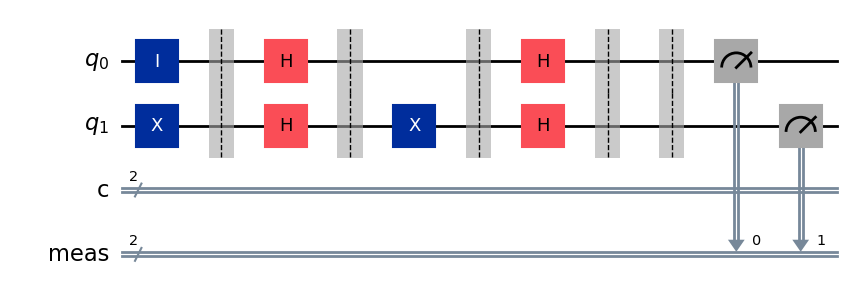

In [ ]:
from qiskit import ClassicalRegister, QuantumRegister, QuantumCircuit
from qiskit_aer import AerSimulator

q = QuantumRegister(2,name='q')
c = ClassicalRegister(2,name='c')
deutsch_qc = QuantumCircuit(q,c,name='qc')

deutsch_qc.id(q[0])
deutsch_qc.x(q[1])
f = Deutsch(deutsch_qc,q)
deutsch_qc.measure_all()

deutsch_qc.draw(output='mpl')

In [ ]:
from qiskit.primitives import StatevectorSampler
sampler = StatevectorSampler()
pub = deutsch_qc
job_sampler = sampler.run([pub], shots=1)

result_sampler = job_sampler.result()
Qubit0_M  = list(result_sampler[0].data.meas.get_counts().keys())[0][1]
if(Qubit0_M=='0'):
    print('Measured State |0>, the function f is constant\n')
else:
    print('Measured State |1>, the function f is balanced\n')
print('Hidden Function ',f)

Measured State |0>, the function f is constant

Hidden Function  f(0,1) -> 1


## A three qubit Oracle

### Constant Oracle
Let's start by creating a constant oracle, in this case the input has no effect on the output so we just randomly set the output qubit to be 0 or 1:

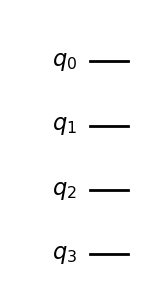

In [ ]:
# set the length of the n-bit input string.
n = 3

const_oracle = QuantumCircuit(n+1)

output = np.random.randint(2)
if output == 1:
    const_oracle.x(n)

const_oracle.draw(output='mpl')

### Balanced Oracle
We can create a balanced oracle by performing CNOTs with each input qubit as a control and the output bit as the target. We can vary the input states that give 0 or 1 by wrapping some of the controls in X-gates. Let's first choose a binary string of length `n` that dictates which controls to wrap:

In [ ]:
b_str = "101"

Now we have this string, we can use it as a key to place our X-gates. For each qubit in our circuit, we place an X-gate if the corresponding digit in `b_str` is `1`, or do nothing if the digit is `0`.

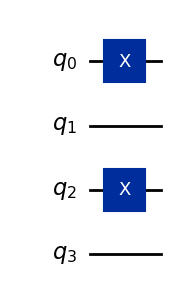

In [ ]:
balanced_oracle = QuantumCircuit(n+1)
# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)
balanced_oracle.draw(output='mpl')

Next, we do our controlled-NOT gates, using each input qubit as a control, and the output qubit as a target:

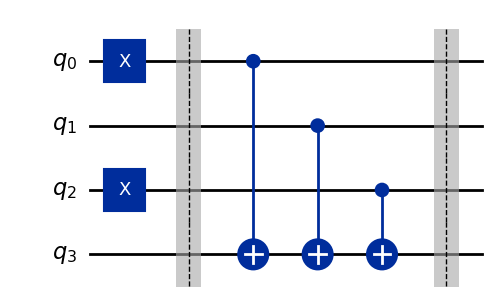

In [ ]:
# Use barrier as divider
balanced_oracle.barrier()

# Controlled-NOT gates
for qubit in range(n):
    balanced_oracle.cx(qubit, n)

balanced_oracle.barrier()
balanced_oracle.draw(output='mpl')

Finally we wrap the controls in X-gates:

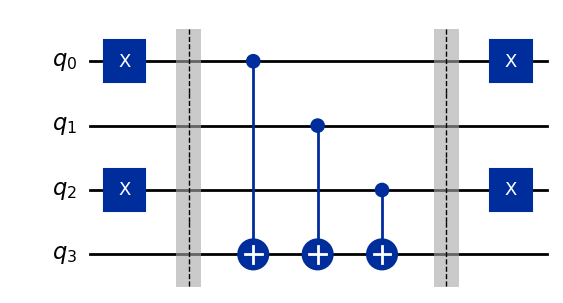

In [ ]:
# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)

# Show oracle
balanced_oracle.draw(output='mpl')

# The Full Algorithm

Let's now put everything together. This first step in the algorithm is to initialize the input qubits in the state $|{+}\rangle$ and the output qubit in the state $|{-}\rangle$:

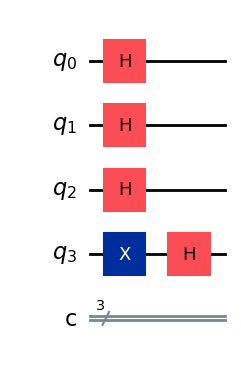

In [ ]:
dj_circuit = QuantumCircuit(n+1, n)

# Apply H-gates
for qubit in range(n):
    dj_circuit.h(qubit)

# Put qubit in state |->
dj_circuit.x(n)
dj_circuit.h(n)
dj_circuit.draw(output='mpl')

Next, let's apply the oracle. Here we apply the `balanced_oracle` we created above:

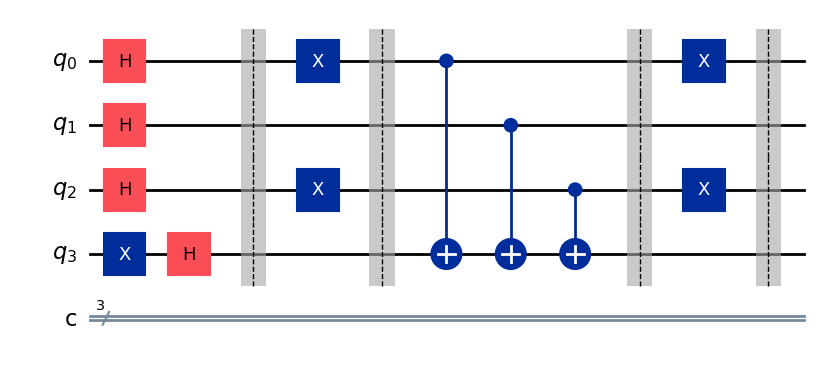

In [ ]:
dj_circuit = QuantumCircuit(n+1, n)

# Apply H-gates
for qubit in range(n):
    dj_circuit.h(qubit)

# Put qubit in state |->
dj_circuit.x(n)
dj_circuit.h(n)
dj_circuit.barrier()
# Add oracle
dj_circuit = dj_circuit.compose(balanced_oracle)
# dj_circuit = dj_circuit.compose(const_oracle)
dj_circuit.barrier()
dj_circuit.draw(output='mpl')

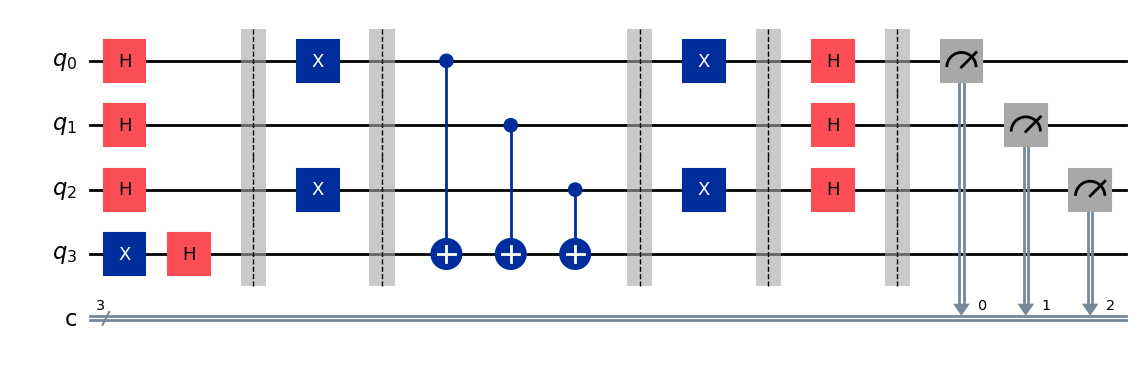

In [ ]:
# Repeat H-gates
for qubit in range(n):
    dj_circuit.h(qubit)
dj_circuit.barrier()

# Measure
for i in range(n):
    dj_circuit.measure(i, i)

# Display circuit
dj_circuit.draw(output='mpl')

### Let's evaluate the output

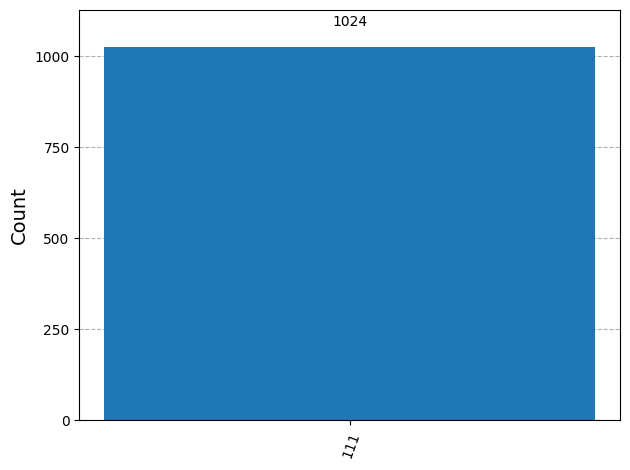

In [ ]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

counts = AerSimulator().run(dj_circuit).result().get_counts()
plot_histogram(counts)

# Let's run on a real device!!

In [ ]:
# Import IBMQ and the job monitoring tool
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv()

IBM_QUANTUM_TOKEN = os.getenv("IBM_QUANTUM_TOKEN_CUA")
IBM_QUANTUM_INSTANCE = os.getenv("IBM_QUANTUM_INSTANCE_CUA_OPEN")

QiskitRuntimeService.save_account(
    token=IBM_QUANTUM_TOKEN,
    instance=IBM_QUANTUM_INSTANCE,
    overwrite=True,
)
service = QiskitRuntimeService()

In [ ]:
backend = service.least_busy(simulator=False, operational=True)
print(backend.configuration().backend_name)

ibm_marrakesh


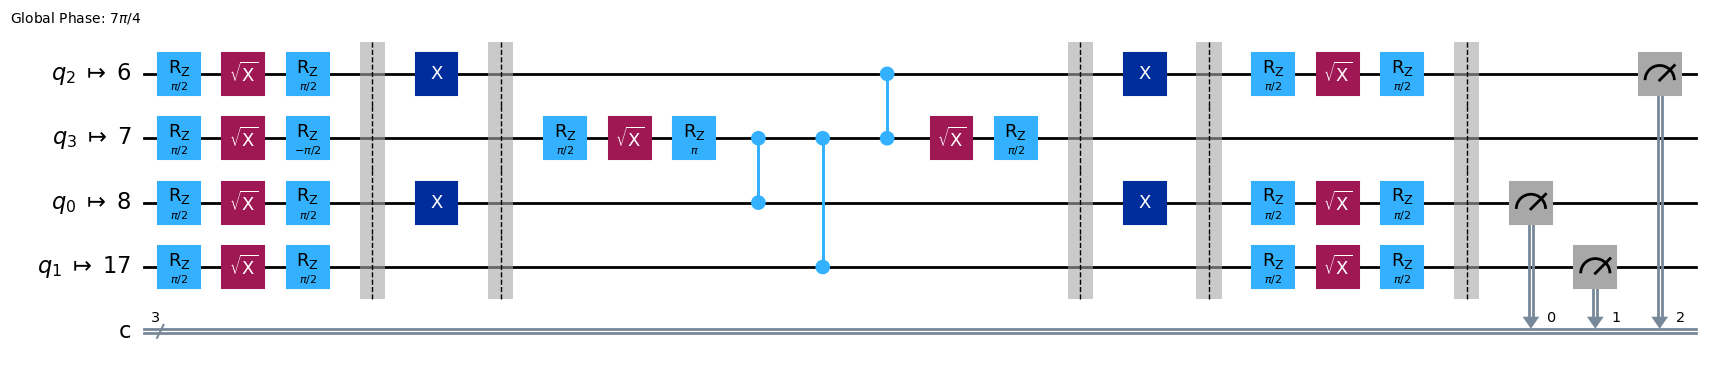

In [ ]:
# Convert to an Instruction Set Architecture (ISA) circuit and layout-mapped observables.
pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
isa_circuit = pm.run(dj_circuit)

isa_circuit.draw('mpl', idle_wires=False)

In [ ]:
# Construct the Sampler instance.
from qiskit_ibm_runtime import SamplerV2 as Sampler
sampler = Sampler(backend)

job = sampler.run([isa_circuit])
print(f">>> Job ID: {job.job_id()}")
print(f">>> Job Status: {job.status()}")

>>> Job ID: d8t2b35posuc738o2mdg
>>> Job Status: QUEUED


In [ ]:
print(f">>> Job Status: {job.status()}")

>>> Job Status: DONE


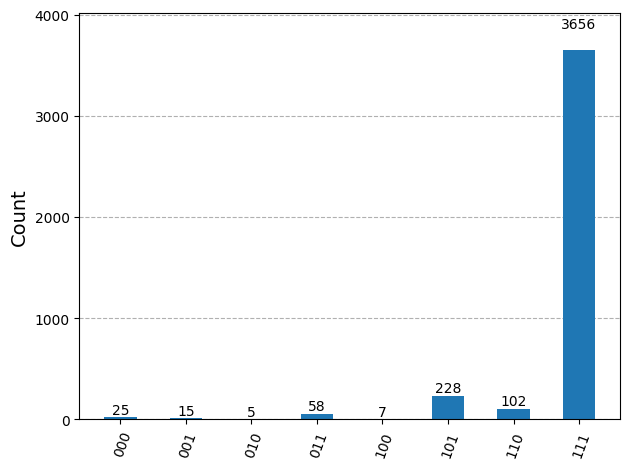

In [ ]:
result = job.result()
plot_histogram(result[0].data.c.get_counts())